In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv('data/iris.csv')

# Display first 5 rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# Display dataset structure and information
print("--- Dataset Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

print("\n--- Species Count ---")
print(df['species'].value_counts())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

--- Summary Statistics ---


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



--- Species Count ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
# Group by species and calculate the mean for each numeric column
df.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [4]:
# Check for missing values in each column
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [5]:
# Calculate correlation matrix for numeric features
df.drop(columns=['species']).corr()

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.117570,0.871754,0.817941
sepal_width,-0.117570,1.000000,-0.428440,-0.366126
petal_length,0.871754,-0.428440,1.000000,0.962865
petal_width,0.817941,-0.366126,0.962865,1.000000


In [6]:
!uv add matplotlib seaborn

Resolved 105 packages in 1ms
Checked 102 packages in 19ms


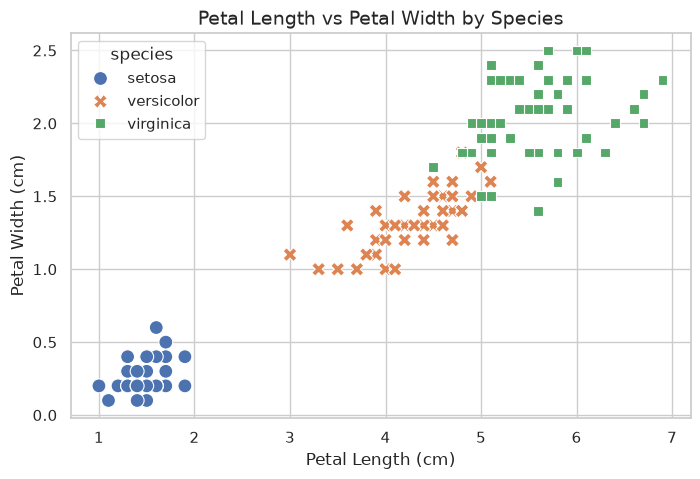

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ضبط خلفية الرسوم
sns.set_theme(style="whitegrid")

# رسم Scatter Plot ملوّن حسب نوع الزهرة
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    style='species', 
    s=100
)

plt.title('Petal Length vs Petal Width by Species', fontsize=14)
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Petal Width (cm)', fontsize=12)
plt.show()

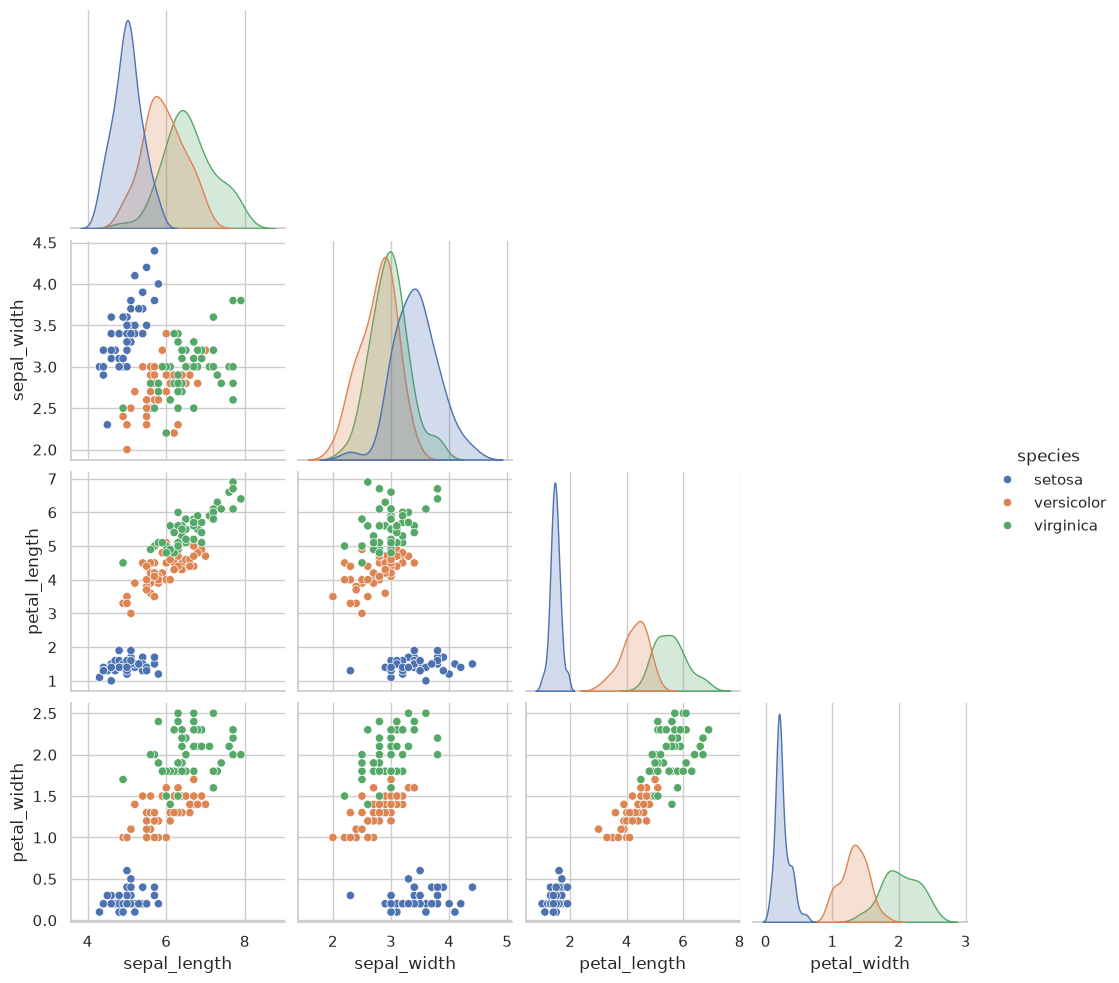

In [8]:
sns.pairplot(df, hue='species', corner=True)
plt.show()

In [9]:
print("--- Last 5 rows ---")
display(df.tail())

print("\n--- Shape (Rows, Columns) ---")
print(df.shape)

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Duplicate Rows Count ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n--- Specific Descriptive Values ---")
print(f"Max Petal Length: {df['petal_length'].max()}")
print(f"Min Sepal Width: {df['sepal_width'].min()}")

--- Last 5 rows ---


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica



--- Shape (Rows, Columns) ---
(150, 5)

--- Column Names ---
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

--- Data Types ---
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

--- Duplicate Rows Count ---
Number of duplicate rows: 1

--- Specific Descriptive Values ---
Max Petal Length: 6.9
Min Sepal Width: 2.0


In [10]:
print("--- 1. Flowers with sepal_length > 6 ---")
display(df[df['sepal_length'] > 6].head())

print("\n--- 2. Flowers with petal_width > 1.5 ---")
display(df[df['petal_width'] > 1.5].head())

print("\n--- 3. Setosa Species Only ---")
display(df[df['species'] == 'setosa'].head())

print("\n--- 4. Species with Highest Average Petal Length ---")
highest_petal_species = df.groupby('species')['petal_length'].mean().idxmax()
print(f"Species with highest avg petal length: {highest_petal_species}")

print("\n--- 5. Dataset Sorted by sepal_length Descending ---")
display(df.sort_values(by='sepal_length', ascending=False).head())

--- 1. Flowers with sepal_length > 6 ---


,sepal_length,sepal_width,petal_length,petal_width,species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
54,6.5,2.8,4.6,1.5,versicolor
56,6.3,3.3,4.7,1.6,versicolor



--- 2. Flowers with petal_width > 1.5 ---


,sepal_length,sepal_width,petal_length,petal_width,species
56,6.3,3.3,4.7,1.6,versicolor
70,5.9,3.2,4.8,1.8,versicolor
77,6.7,3.0,5.0,1.7,versicolor
83,6.0,2.7,5.1,1.6,versicolor
85,6.0,3.4,4.5,1.6,versicolor



--- 3. Setosa Species Only ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



--- 4. Species with Highest Average Petal Length ---
Species with highest avg petal length: virginica

--- 5. Dataset Sorted by sepal_length Descending ---


,sepal_length,sepal_width,petal_length,petal_width,species
131,7.9,3.8,6.4,2.0,virginica
122,7.7,2.8,6.7,2.0,virginica
118,7.7,2.6,6.9,2.3,virginica
117,7.7,3.8,6.7,2.2,virginica
135,7.7,3.0,6.1,2.3,virginica


In [11]:
import os


os.makedirs('output', exist_ok=True)


species_summary = df.groupby('species').describe()
species_summary.to_csv('output/species_summary.csv')


filtered_df = df[df['sepal_length'] > 6]
filtered_df.to_csv('output/filtered_iris.csv', index=False)

print("Both files created successfully in the 'output/' folder!")

Both files created successfully in the 'output/' folder!
